In [1]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("fast_food_cheat_meal_workout_burn.csv")

In [3]:
df.head()

,order_id,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,...,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,FFC-00001,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,...,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,FFC-00002,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,...,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,FFC-00003,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,...,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll
3,FFC-00004,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,...,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7,Extreme / Half-Marathon Toll
4,FFC-00005,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,...,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2,Severe Cardio Deficit


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   order_id                     8000 non-null   str    
 1   fast_food_chain              8000 non-null   str    
 2   meal_category                8000 non-null   str    
 3   item_count                   8000 non-null   int64  
 4   total_calories               8000 non-null   int64  
 5   fat_grams                    8000 non-null   int64  
 6   saturated_fat_grams          8000 non-null   int64  
 7   carb_grams                   8000 non-null   int64  
 8   sugar_grams                  8000 non-null   int64  
 9   protein_grams                8000 non-null   int64  
 10  sodium_mg                    8000 non-null   int64  
 11  consumer_gender              8000 non-null   str    
 12  consumer_age                 8000 non-null   int64  
 13  consumer_weight_kg           

In [5]:
df.describe()

,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,consumer_age,consumer_weight_kg,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,3.502125,1602.574375,80.061375,31.985125,165.961375,62.250750,54.037250,2399.537000,41.482375,77.804587,121.555850,1481.018525,350.152287,165.043288,117.917537,100.487000,80.128575
std,1.118996,672.128080,34.288636,14.401470,70.790342,31.795058,30.690342,1072.813548,13.932712,13.929379,52.717465,622.806400,164.466555,77.544694,55.491633,47.268065,33.606582
min,2.000000,750.000000,32.000000,10.000000,66.000000,14.000000,15.000000,826.000000,18.000000,48.000000,47.100000,675.500000,100.500000,42.000000,26.300000,22.900000,37.500000
25%,2.000000,1080.000000,53.000000,21.000000,110.000000,39.000000,30.000000,1564.000000,29.000000,68.000000,79.200000,997.350000,224.875000,106.200000,76.100000,64.700000,54.000000
50%,4.000000,1479.000000,74.000000,29.000000,153.000000,55.000000,48.000000,2192.000000,42.000000,77.600000,112.200000,1366.950000,319.150000,149.950000,107.400000,91.450000,74.000000
75%,5.000000,2008.000000,100.000000,40.000000,208.000000,79.000000,71.000000,3009.250000,54.000000,87.200000,152.725000,1854.300000,439.700000,207.425000,147.500000,126.200000,100.400000
max,5.000000,3600.000000,190.000000,75.000000,380.000000,175.000000,140.000000,5800.000000,65.000000,129.400000,291.100000,3429.200000,1299.200000,614.600000,436.500000,369.500000,180.000000


In [6]:
df["fast_food_chain"].value_counts()

fast_food_chain
McDonald's        1748
Burger King       1173
Taco Bell         1146
Wendy's           1061
Domino's Pizza     858
Five Guys          635
KFC                581
Subway             475
Starbucks          323
Name: count, dtype: int64

In [7]:
df["meal_category"].value_counts()

meal_category
Loaded Burrito, Nachos & Soda     1399
Double Burger & Large Fry         1364
Late-Night Value Menu Binge       1357
Pizza Feast & Cheesy Bread        1321
Fried Chicken Bucket & Slaw       1281
Dessert Overload & Large Shake    1278
Name: count, dtype: int64

In [8]:
df["consumer_gender"].value_counts()

consumer_gender
Male      4291
Female    3709
Name: count, dtype: int64

In [9]:
df["fitness_level"].value_counts()

fitness_level
Sedentary            3624
Moderately Active    3172
Highly Trained       1204
Name: count, dtype: int64

In [10]:
df["workout_shock_tier"].value_counts()

workout_shock_tier
Extreme / Half-Marathon Toll    3257
Severe Cardio Deficit           2429
High Sweat Penalty              2122
Moderate Burn                    192
Name: count, dtype: int64

C:\Users\onurs\AppData\Local\Temp\ipykernel_21852\3777848420.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


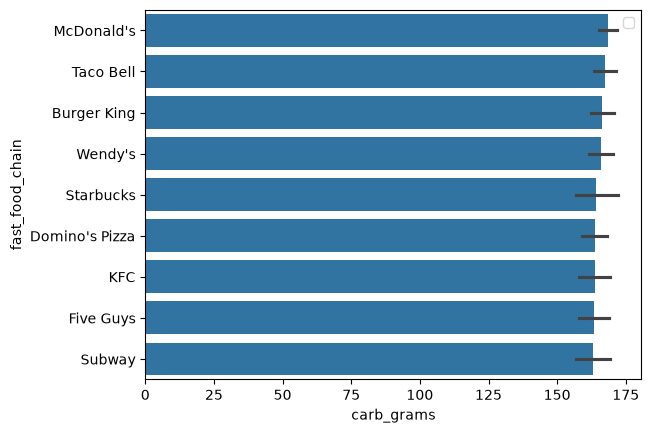

In [11]:
sns.barplot(x=df["carb_grams"],y=df["fast_food_chain"],estimator="mean",order=df.groupby("fast_food_chain")["carb_grams"].mean().sort_values(ascending=False).index)
plt.legend()
plt.show()

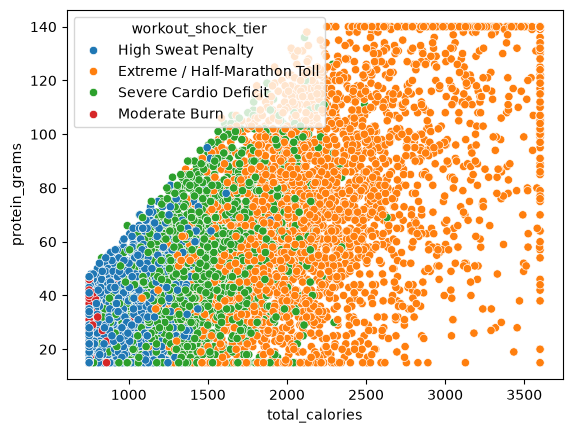

In [12]:
sns.scatterplot(data=df,x="total_calories",y="protein_grams",hue="workout_shock_tier")
plt.show()

In [13]:
df.drop("order_id",axis=1,inplace=True)

In [14]:
df.head()

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,...,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,...,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,...,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,...,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,...,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7,Extreme / Half-Marathon Toll
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,...,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2,Severe Cardio Deficit


In [15]:
pd.set_option("display.max_columns",None)
pd.set_option("display.width",None)
df.head()

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,consumer_gender,consumer_age,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,Male,61,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,Female,65,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,Female,35,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,Female,61,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7,Extreme / Half-Marathon Toll
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,Male,19,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2,Severe Cardio Deficit


In [16]:
df.groupby(["fast_food_chain","meal_category"])["total_calories"].agg(["count","mean","median","min","max"])

count         mean  median  \
fast_food_chain meal_category                                                
Burger King     Dessert Overload & Large Shake    175  1544.748571  1404.0   
                Double Burger & Large Fry         193  1648.062176  1488.0   
                Fried Chicken Bucket & Slaw       178  1550.337079  1398.0   
                Late-Night Value Menu Binge       230  1626.786957  1510.5   
                Loaded Burrito, Nachos & Soda     205  1618.580488  1579.0   
                Pizza Feast & Cheesy Bread        192  1614.927083  1517.0   
Domino's Pizza  Dessert Overload & Large Shake    147  1630.197279  1549.0   
                Double Burger & Large Fry         158  1586.860759  1460.0   
                Fried Chicken Bucket & Slaw       131  1564.557252  1405.0   
                Late-Night Value Menu Binge       142  1534.697183  1404.0   
                Loaded Burrito, Nachos & Soda     141  1615.595745  1500.0   
                Pizza Feast & Cheesy Bread        139  1566.381295  1466.0   
Five Guys       Dessert Overload & Large Shake    117  1641.589744  1463.0   
                Double Burger & Large Fry         104  1584.019231  1448.0   
                Fried Chicken Bucket & Slaw       104  1578.750000  1448.5   
                Late-Night Value Menu Binge       104  1468.144231  1357.5   
                Loaded Burrito, Nachos & Soda      97  1613.072165  1577.0   
                Pizza Feast & Cheesy Bread        109  1558.798165  1394.0   
KFC             Dessert Overload & Large Shake     99  1637.030303  1546.0   
                Double Burger & Large Fry          89  1585.494382  1480.0   
                Fried Chicken Bucket & Slaw       111  1630.378378  1408.0   
                Late-Night Value Menu Binge        90  1521.755556  1368.0   
                Loaded Burrito, Nachos & Soda      98  1465.285714  1390.5   
                Pizza Feast & Cheesy Bread         94  1627.436170  1474.5   
McDonald's      Dessert Overload & Large Shake    290  1613.017241  1521.0   
                Double Burger & Large Fry         321  1600.239875  1535.0   
                Fried Chicken Bucket & Slaw       268  1615.164179  1494.5   
                Late-Night Value Menu Binge       269  1620.360595  1478.0   
                Loaded Burrito, Nachos & Soda     319  1660.319749  1516.0   
                Pizza Feast & Cheesy Bread        281  1620.135231  1497.0   
Starbucks       Dessert Overload & Large Shake     46  1493.913043  1298.5   
                Double Burger & Large Fry          45  1695.400000  1526.0   
                Fried Chicken Bucket & Slaw        53  1668.566038  1487.0   
                Late-Night Value Menu Binge        56  1559.160714  1486.0   
                Loaded Burrito, Nachos & Soda      61  1631.852459  1588.0   
                Pizza Feast & Cheesy Bread         62  1497.064516  1340.0   
Subway          Dessert Overload & Large Shake     71  1538.704225  1401.0   
                Double Burger & Large Fry          79  1538.683544  1369.0   
                Fried Chicken Bucket & Slaw        80  1586.950000  1449.5   
                Late-Night Value Menu Binge        85  1706.788235  1550.0   
                Loaded Burrito, Nachos & Soda      81  1509.061728  1474.0   
                Pizza Feast & Cheesy Bread         79  1609.430380  1458.0   
Taco Bell       Dessert Overload & Large Shake    169  1603.230769  1468.0   
                Double Burger & Large Fry         195  1609.497436  1512.0   
                Fried Chicken Bucket & Slaw       170  1586.747059  1454.5   
                Late-Night Value Menu Binge       198  1636.010101  1500.0   
                Loaded Burrito, Nachos & Soda     229  1567.598253  1443.0   
                Pizza Feast & Cheesy Bread        185  1722.216216  1638.0   
Wendy's         Dessert Overload & Large Shake    164  1704.121951  1649.5   
                Double Burger & Large Fry         180  1585.266667  14

In [17]:
df.groupby(["fast_food_chain","meal_category"])["total_calories"].agg(["count","mean","median","min","max"])

count         mean  median  \
fast_food_chain meal_category                                                
Burger King     Dessert Overload & Large Shake    175  1544.748571  1404.0   
                Double Burger & Large Fry         193  1648.062176  1488.0   
                Fried Chicken Bucket & Slaw       178  1550.337079  1398.0   
                Late-Night Value Menu Binge       230  1626.786957  1510.5   
                Loaded Burrito, Nachos & Soda     205  1618.580488  1579.0   
                Pizza Feast & Cheesy Bread        192  1614.927083  1517.0   
Domino's Pizza  Dessert Overload & Large Shake    147  1630.197279  1549.0   
                Double Burger & Large Fry         158  1586.860759  1460.0   
                Fried Chicken Bucket & Slaw       131  1564.557252  1405.0   
                Late-Night Value Menu Binge       142  1534.697183  1404.0   
                Loaded Burrito, Nachos & Soda     141  1615.595745  1500.0   
                Pizza Feast & Cheesy Bread        139  1566.381295  1466.0   
Five Guys       Dessert Overload & Large Shake    117  1641.589744  1463.0   
                Double Burger & Large Fry         104  1584.019231  1448.0   
                Fried Chicken Bucket & Slaw       104  1578.750000  1448.5   
                Late-Night Value Menu Binge       104  1468.144231  1357.5   
                Loaded Burrito, Nachos & Soda      97  1613.072165  1577.0   
                Pizza Feast & Cheesy Bread        109  1558.798165  1394.0   
KFC             Dessert Overload & Large Shake     99  1637.030303  1546.0   
                Double Burger & Large Fry          89  1585.494382  1480.0   
                Fried Chicken Bucket & Slaw       111  1630.378378  1408.0   
                Late-Night Value Menu Binge        90  1521.755556  1368.0   
                Loaded Burrito, Nachos & Soda      98  1465.285714  1390.5   
                Pizza Feast & Cheesy Bread         94  1627.436170  1474.5   
McDonald's      Dessert Overload & Large Shake    290  1613.017241  1521.0   
                Double Burger & Large Fry         321  1600.239875  1535.0   
                Fried Chicken Bucket & Slaw       268  1615.164179  1494.5   
                Late-Night Value Menu Binge       269  1620.360595  1478.0   
                Loaded Burrito, Nachos & Soda     319  1660.319749  1516.0   
                Pizza Feast & Cheesy Bread        281  1620.135231  1497.0   
Starbucks       Dessert Overload & Large Shake     46  1493.913043  1298.5   
                Double Burger & Large Fry          45  1695.400000  1526.0   
                Fried Chicken Bucket & Slaw        53  1668.566038  1487.0   
                Late-Night Value Menu Binge        56  1559.160714  1486.0   
                Loaded Burrito, Nachos & Soda      61  1631.852459  1588.0   
                Pizza Feast & Cheesy Bread         62  1497.064516  1340.0   
Subway          Dessert Overload & Large Shake     71  1538.704225  1401.0   
                Double Burger & Large Fry          79  1538.683544  1369.0   
                Fried Chicken Bucket & Slaw        80  1586.950000  1449.5   
                Late-Night Value Menu Binge        85  1706.788235  1550.0   
                Loaded Burrito, Nachos & Soda      81  1509.061728  1474.0   
                Pizza Feast & Cheesy Bread         79  1609.430380  1458.0   
Taco Bell       Dessert Overload & Large Shake    169  1603.230769  1468.0   
                Double Burger & Large Fry         195  1609.497436  1512.0   
                Fried Chicken Bucket & Slaw       170  1586.747059  1454.5   
                Late-Night Value Menu Binge       198  1636.010101  1500.0   
                Loaded Burrito, Nachos & Soda     229  1567.598253  1443.0   
                Pizza Feast & Cheesy Bread        185  1722.216216  1638.0   
Wendy's         Dessert Overload & Large Shake    164  1704.121951  1649.5   
                Double Burger & Large Fry         180  1585.266667  14

In [18]:
df.head()

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,consumer_gender,consumer_age,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,Male,61,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,Female,65,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,Female,35,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,Female,61,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7,Extreme / Half-Marathon Toll
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,Male,19,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2,Severe Cardio Deficit


In [19]:
df.head()

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,consumer_gender,consumer_age,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,Male,61,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,Female,65,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,Female,35,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,Female,61,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7,Extreme / Half-Marathon Toll
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,Male,19,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2,Severe Cardio Deficit


<Axes: >

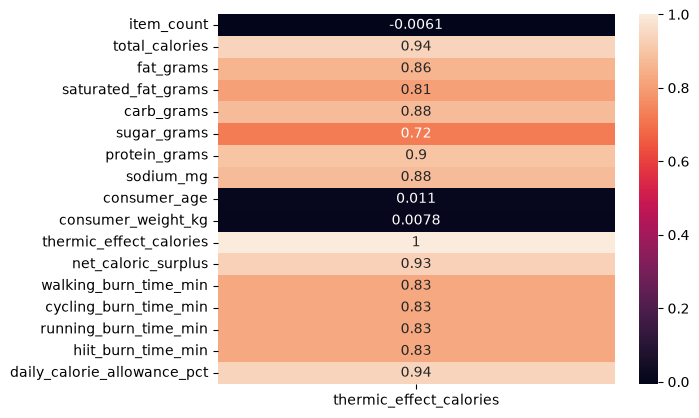

In [20]:
sns.heatmap(df.select_dtypes(include="number").corr()[["thermic_effect_calories"]],annot=True)

<Axes: >

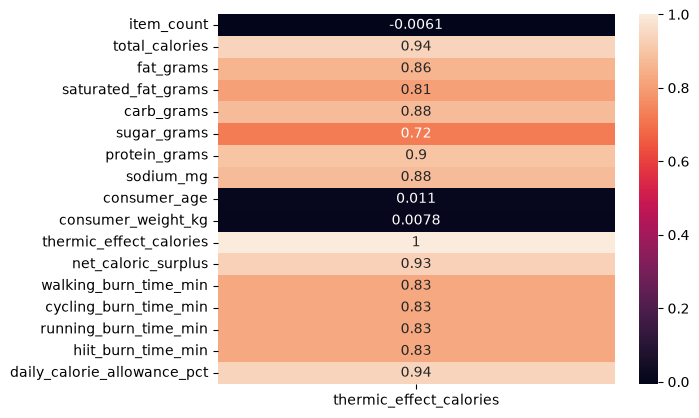

In [21]:
sns.heatmap(df.select_dtypes(include="number").corr()[["thermic_effect_calories"]],annot=True)

<Axes: >

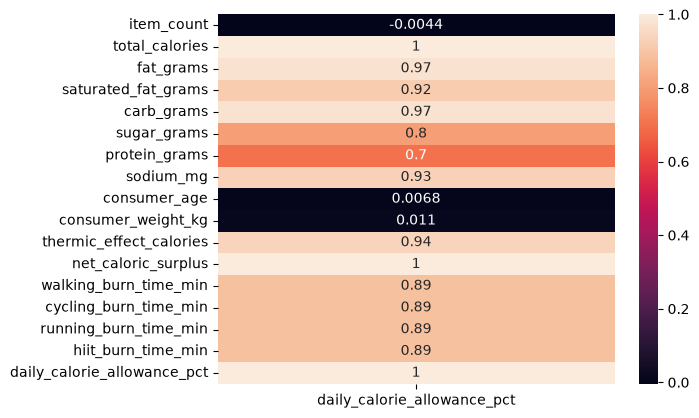

In [22]:
sns.heatmap(df.select_dtypes(include="number").corr()[["daily_calorie_allowance_pct"]],annot=True)

In [23]:
df.head()

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,consumer_gender,consumer_age,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,Male,61,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,Female,65,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,Female,35,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,Female,61,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7,Extreme / Half-Marathon Toll
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,Male,19,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2,Severe Cardio Deficit


In [24]:
df.drop(["walking_burn_time_min",	
         "cycling_burn_time_min","running_burn_time_min",
         "hiit_burn_time_min"],axis=1,inplace=True)

In [25]:
df.head()

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,consumer_gender,consumer_age,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,daily_calorie_allowance_pct,workout_shock_tier
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,Male,61,96.0,Moderately Active,77.9,937.1,50.7,High Sweat Penalty
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,Female,65,53.6,Moderately Active,136.7,1712.3,92.4,Extreme / Half-Marathon Toll
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,Female,35,67.0,Moderately Active,135.0,1785.0,96.0,Extreme / Half-Marathon Toll
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,Female,61,62.6,Sedentary,82.3,1172.7,62.7,Extreme / Half-Marathon Toll
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,Male,19,73.0,Moderately Active,127.4,1537.6,83.2,Severe Cardio Deficit


In [26]:
drop_cols=["thermic_effect_calories",
    "net_caloric_surplus",
    "daily_calorie_allowance_pct"]

In [27]:
X=df.drop(columns=["workout_shock_tier"]+drop_cols)
y=df["workout_shock_tier"]

In [28]:
X

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,consumer_gender,consumer_age,consumer_weight_kg,fitness_level
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,Male,61,96.0,Moderately Active
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,Female,65,53.6,Moderately Active
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,Female,35,67.0,Moderately Active
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,Female,61,62.6,Sedentary
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,Male,19,73.0,Moderately Active
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,Burger King,Fried Chicken Bucket & Slaw,2,1762,84,29,170,77,82,3039,Male,20,72.1,Highly Trained
7996,Subway,Fried Chicken Bucket & Slaw,3,2818,152,57,326,88,37,4337,Male,25,105.4,Sedentary
7997,Wendy's,Pizza Feast & Cheesy Bread,5,1240,63,27,126,48,43,1758,Male,56,114.9,Sedentary
7998,KFC,Fried Chicken Bucket & Slaw,4,1825,78,27,179,87,102,2940,Female,48,52.3,Moderately Active


In [29]:
y

0                 High Sweat Penalty
1       Extreme / Half-Marathon Toll
2       Extreme / Half-Marathon Toll
3       Extreme / Half-Marathon Toll
4              Severe Cardio Deficit
                    ...             
7995           Severe Cardio Deficit
7996    Extreme / Half-Marathon Toll
7997              High Sweat Penalty
7998    Extreme / Half-Marathon Toll
7999    Extreme / Half-Marathon Toll
Name: workout_shock_tier, Length: 8000, dtype: str

In [30]:
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,StandardScaler

In [31]:
categorial_cols=X.select_dtypes(include=["object","string"]).columns.tolist()

In [32]:
numerical_cols=X.select_dtypes(include="number").columns.tolist()

In [33]:
label_encoder=LabelEncoder()

In [34]:
y=label_encoder.fit_transform(y)

In [35]:
from sklearn.model_selection import train_test_split

In [36]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [37]:
encoder=OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)
X_train_encoder=encoder.fit_transform(X_train[categorial_cols])
X_test_encoder=encoder.transform(X_test[categorial_cols])

In [38]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train[numerical_cols])
X_test_scaled=scaler.transform(X_test[numerical_cols])

In [39]:
X_train=np.hstack((X_train_encoder,X_train_scaled))
X_test=np.hstack((X_test_encoder,X_test_scaled))

In [40]:
print(X_train.shape)
print(X_test.shape)

(6400, 30)
(1600, 30)


In [41]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(6400, 30)
(1600, 30)
(6400,)
(1600,)


In [42]:
X_train=torch.tensor(X_train,dtype=torch.float32)
X_test=torch.tensor(X_test,dtype=torch.float32)

y_train=torch.tensor(y_train,dtype=torch.long)
y_test=torch.tensor(y_test,dtype=torch.long)

In [43]:
from torch import nn

In [44]:
class FoodClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear_layer_stack=nn.Sequential(
            nn.Linear(30,64),
            nn.ReLU(),
            nn.Linear(64,64),
            nn.ReLU(),
            nn.Linear(64,4)
        )
    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.linear_layer_stack(x)

In [45]:
torch.manual_seed(42)
model=FoodClassifier()
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(params=model.parameters(),lr=0.001)

In [46]:
from torchmetrics.classification import MulticlassAccuracy
accuarcy=MulticlassAccuracy(num_classes=4,average="micro")

In [47]:
train_losses=[]
test_losses=[]
train_acc=[]
test_accu=[]
epochs=300
for epoch in range(epochs):
    model.train()
    logits=model(X_train)
    loss=loss_fn(logits,y_train)

    pred=torch.softmax(logits,dim=1).argmax(dim=1)
    acc=accuarcy(pred,y_train).item()*100

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.inference_mode():
        test_logits=model(X_test)
        test_loss=loss_fn(test_logits,y_test)

        test_pred=torch.softmax(test_logits,dim=1).argmax(dim=1)
        test_acc=accuarcy(test_pred,y_test).item()*100

        train_losses.append(loss.item())
        test_losses.append(test_loss.item())
        
        train_acc.append(acc)
        test_accu.append(test_acc)
    if epoch % 20 ==0:
        print(f"Epoch:{epoch}, loss:{loss},Accuracy:{acc},Test Loss:{test_loss},Test Accuarcy:{test_acc}")

Epoch:0, loss:1.3936702013015747,Accuracy:19.031250476837158,Test Loss:1.3786232471466064,Test Accuarcy:29.499998688697815
Epoch:20, loss:1.055172085762024,Accuracy:55.281251668930054,Test Loss:1.0421466827392578,Test Accuarcy:53.75000238418579
Epoch:40, loss:0.6922378540039062,Accuracy:78.75000238418579,Test Loss:0.7016451358795166,Test Accuarcy:76.2499988079071
Epoch:60, loss:0.4949801564216614,Accuracy:85.10937690734863,Test Loss:0.5084083676338196,Test Accuarcy:81.99999928474426
Epoch:80, loss:0.3675828278064728,Accuracy:89.43750262260437,Test Loss:0.3798243999481201,Test Accuarcy:87.93749809265137
Epoch:100, loss:0.2881711423397064,Accuracy:91.10937714576721,Test Loss:0.30058756470680237,Test Accuarcy:90.56249856948853
Epoch:120, loss:0.23954607546329498,Accuracy:92.25000143051147,Test Loss:0.250564843416214,Test Accuarcy:91.00000262260437
Epoch:140, loss:0.20606379210948944,Accuracy:92.98437237739563,Test Loss:0.21777673065662384,Test Accuarcy:91.31249785423279
Epoch:160, loss:0.

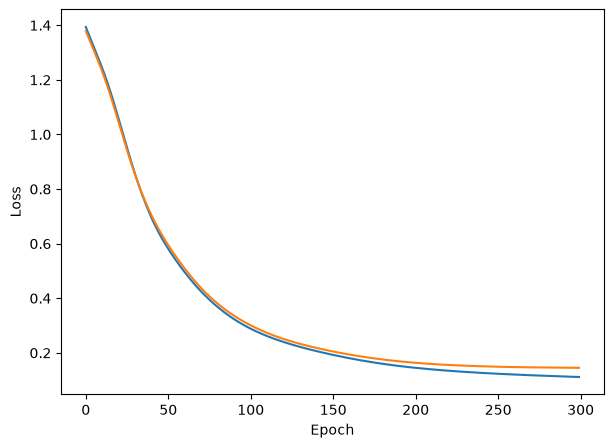

In [48]:
plt.figure(figsize=(7,5))
plt.plot(train_losses,label="Train loss")
plt.plot(test_losses,label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

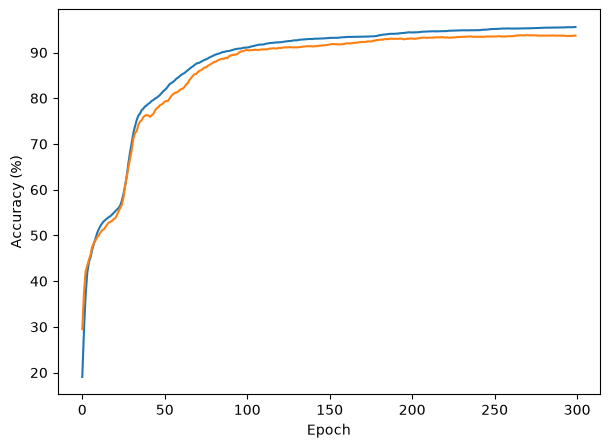

In [49]:
plt.figure(figsize=(7,5))
plt.plot(train_acc,label="Train acc")
plt.plot(test_accu,label="Test acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.show()

In [51]:
from torchmetrics.classification import MulticlassConfusionMatrix

In [52]:
cm=MulticlassConfusionMatrix(num_classes=4)
matrix=cm(test_pred,y_test)
print(matrix)

tensor([[634,   0,   0,  18],
        [  0, 400,   4,  20],
        [  0,  15,  23,   0],
        [ 25,  19,   0, 442]])


In [53]:
from torchmetrics.utilities.plot import plot_confusion_matrix

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

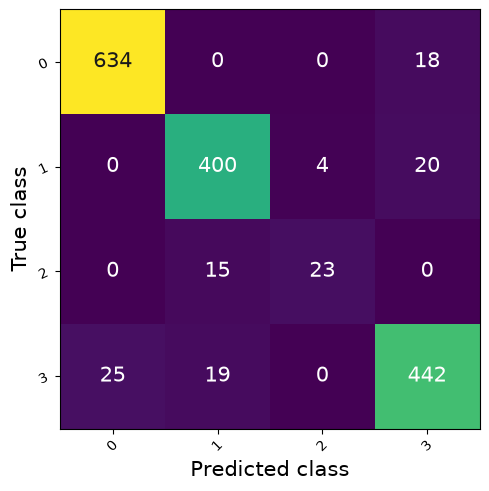

In [54]:
plot_confusion_matrix(matrix)

In [55]:
from pathlib import Path

In [56]:
MODEL_PATH=Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME="food_classification_model.pth"
MODEL_SAVE_PATH=MODEL_PATH/MODEL_NAME

torch.save(obj=model.state_dict(),f=MODEL_SAVE_PATH)